# 02 · Release detection
Replays every clip through the detector (`airhoops_lab/detector.py`, a line-for-line port of
`throwDetector.ts`) and scores it against the Week 3 targets:
**≥ 90 % of throws detected, < 10 % of non-throws trigger.**

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from airhoops_lab.load import load_all
clips = load_all()
print(f"{len(clips)} clips loaded")

6 clips loaded


In [2]:
from airhoops_lab.evaluate import evaluate, report
metrics, table = evaluate(clips)
report(metrics, table)

    clip        label  hand  fps  events                                                                                                                            event_t
c20e27fe        throw right 15.0       1                                                                                                                             [2600]
fe0637f3        throw  left 18.1       2                                                                                                                       [1168, 2435]
f5a0f8e1        throw right 19.5       1                                                                                                                            [28638]
7524a102 scratch_head right 24.2       0                                                                                                                                 []
ffb442d7         wave  left 15.9       0                                                                                                    

## What the detector saw
Shading = detector state, green line = emitted throw, dotted lines = `min_peak_speed` / `min_extension`.

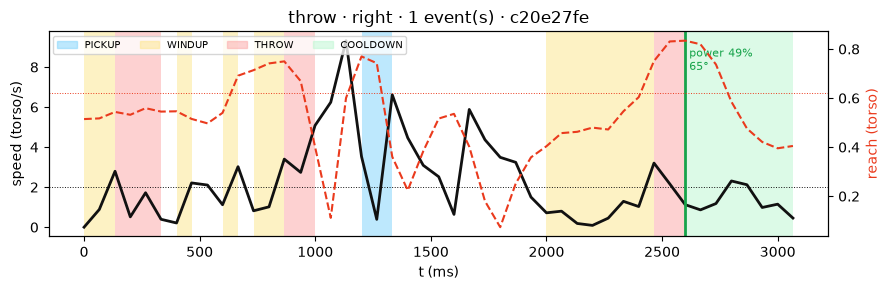

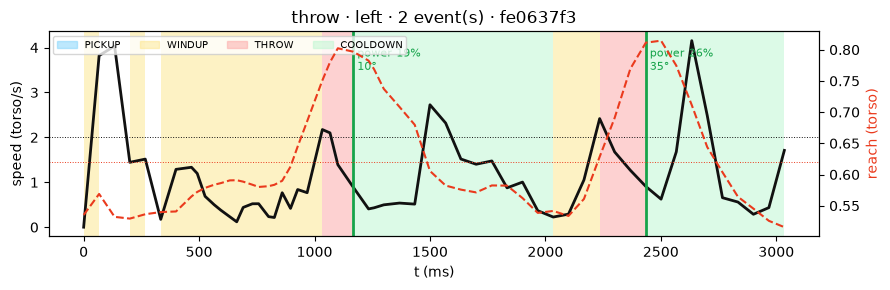

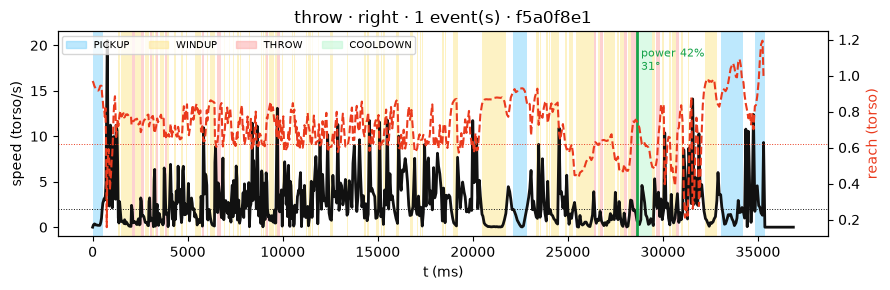

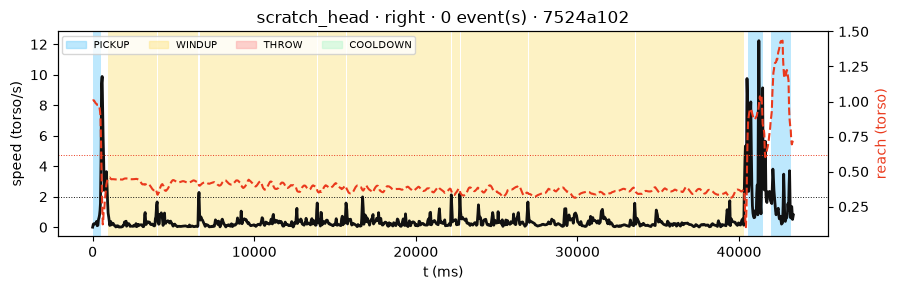

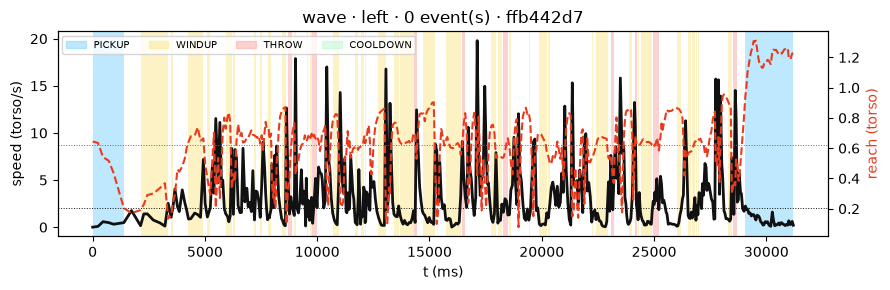

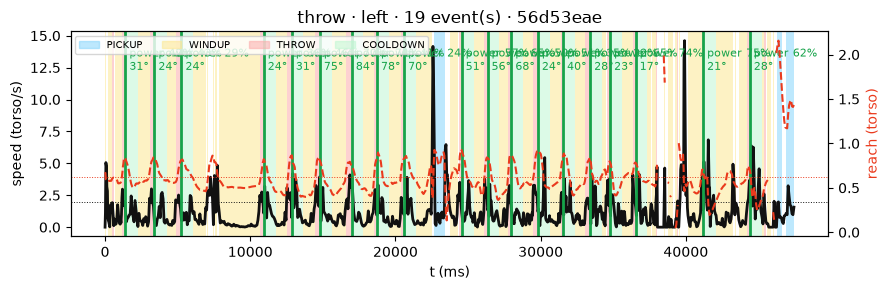

In [3]:
from airhoops_lab.plots import plot_detection
for c in clips:
    plot_detection(c)
    plt.tight_layout(); plt.show()

## Sensitivity
How the number of events changes with the two most important thresholds. With few clips this is
for intuition only — use `python -m airhoops_lab.evaluate --tune` once you have ≥5 clips per class.

In [4]:
from dataclasses import replace
from airhoops_lab.detector import PARAMS, run
from airhoops_lab.kinematics import arm_features
feats = {c.id: arm_features(c) for c in clips}
rows = []
for gain in [0.05, 0.1, 0.15, 0.2, 0.3]:
    for peak in [1.5, 2.0, 2.5, 3.0, 4.0]:
        p = replace(PARAMS, min_extension_gain=gain, min_peak_speed=peak)
        n_throw = sum(len(run(feats[c.id], c.hand, p)[0]) for c in clips if c.is_throw)
        n_other = sum(len(run(feats[c.id], c.hand, p)[0]) for c in clips if not c.is_throw)
        rows.append({"min_extension_gain": gain, "min_peak_speed": peak, "events in throws": n_throw, "events in non-throws": n_other})
pd.DataFrame(rows).pivot(index="min_extension_gain", columns="min_peak_speed", values="events in throws")

min_peak_speed,1.5,2.0,2.5,3.0,4.0
min_extension_gain,,,,,
0.05,25,25,21,15,3
0.10,23,23,19,13,3
0.15,22,22,18,12,2
0.20,20,20,16,10,2
0.30,11,11,10,7,1


## Keep TypeScript in sync
After changing `Params`, copy the values to `DEFAULT_THROW_PARAMS` in `throwDetector.ts` and run
`python -m airhoops_lab.parity` → `npm test` in the frontend. The replay test fails if the two drift.